In [1]:
# =====================================
# HMM CNN EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_hmm_cnn_classifier import RunHmmCnnClassifier
from src.run.preprocess.config import _project_path

In [3]:
import os
import re
import itertools
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# =========================================================
# TEST: combinazioni di feature date all'HMM
# Runner: HMM + CNN con validation NON segmentato (train seg - val no)
# (la CNN riceve sempre le stesse feature)
# Ogni combinazione di feature ingegnerizzate viene testata
# sia senza feature base sia insieme alla coordinata y;
# si aggiunge inoltre la sola y.
# =========================================================

combos = [
    c
    for r in range(1, 5)      # 1..4: singole, coppie, terne, tutte
    for c in itertools.combinations(
        ("speed", "velocity", "pressure_derivative", "acceleration"), r
    )
]

hmm_bases = [(), ("y",)]

configs = [(base, combo) for base in hmm_bases for combo in combos]
configs.append((("y",), ()))     # solo y

print(f"{len(configs)} configurazioni:",
      ["+".join(b + c) for b, c in configs])

rows = []

for base, combo in configs:

    label = ",".join(base + combo)

    print(f"\n=== HMM features: {label} ===")

    output_dir = _project_path(
        f"experiments/test_iperparametri/"
        f"hmm_cnn(train seg - val no)/"
        f"hmm_features_engineered/"
        f"{re.sub(r'[^A-Za-z0-9]+', '_', label)}"
    )

    summary_path = os.path.join(output_dir, "summary.csv")

    try:
        # se l'esperimento è già stato eseguito, legge i risultati senza rilanciarlo
        if os.path.exists(summary_path):
            print("  [SKIP] summary.csv già presente")
            averages = pd.read_csv(summary_path).iloc[0].to_dict()

        else:
            runner = RunHmmCnnClassifier(
                data_root=_project_path(
                    "PaHaW/PaHaW/PaHaW_public"
                ),

                metadata_path=_project_path(
                    "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
                ),

                # =====================================================
                # Configurazione dati
                # =====================================================

                tasks=[8],

                feature_names=("y",),

                engineered_features=(
                    "speed","velocity", "pressure_derivative",
                ),

                hmm_feature_names=base,
                hmm_engineered_features=combo,

                pad_to=256,

                # =====================================================
                # Training
                # =====================================================

                epochs=50,

                batch_size=16,

                learning_rate=1e-3,

                regularization=1e-3,

                # =====================================================
                # HMM
                # =====================================================

                n_states=2,
                covariance_type="diag",
                n_iter=100,
                tol=1e-3,
                random_state=42,
                algorithm="viterbi",
                verbose=False,

                n_splits=5,

                normalize=True,

                seed=42,

                device=(
                    "cuda"
                    if torch.cuda.is_available()
                    else "cpu"
                ),

                output_dir=output_dir,

                training_cfg={
                    "metrics": [
                        "accuracy",
                        "f1",
                        "auc",
                        "precision",
                        "recall",
                        "specificity",
                    ],

                    "monitor_metric": "auc",

                    "early_stopping_patience": float("inf"),

                    "min_delta": 0.0,

                    "normalize": True,

                    "normalization_eps": 1e-6,

                    "results_writer": "csv",

                    "save_metrics": True,
                },
            )

            summary = runner.run()
            averages = summary["averages"]

    except Exception as e:      # una combinazione che fallisce non ferma il test
        print(f"  ERRORE su '{label}': {type(e).__name__}: {e}")
        continue

    row = {
        "hmm_features": label,
        "with_y": "y" in base,
        "n_features": len(base) + len(combo),
    }

    row.update(averages)

    rows.append(row)

if not rows:
    raise RuntimeError("Nessuna combinazione è andata a buon fine.")


# =========================================================
# DATAFRAME
# =========================================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

df = pd.DataFrame(rows)

# a parità di accuracy ordina per AUC, poi per F1
df["_acc_key"] = df["last_val_accuracy"].round(4)

df = df.sort_values(
    ["_acc_key", "last_val_auc", "last_val_f1"],
    ascending=False
).drop(columns="_acc_key").reset_index(drop=True)

df.to_csv(
    "hmm_engineered_features_test_summary_val_no.csv",
    index=False
)

print("\n=== Summary (last epoch) ===")
print(
    df[["hmm_features"] + [f"last_val_{m}" for m in metrics]]
    .round(4)
    .to_string(index=False)
)

# confronto diretto: stessa combinazione senza e con y
print("\n=== Effetto dell'aggiunta di y (last epoch) ===")
cmp_rows = []
for combo in combos:
    lab = ",".join(combo)
    lab_y = ",".join(("y",) + combo)
    a = df[df["hmm_features"] == lab]
    b = df[df["hmm_features"] == lab_y]
    if len(a) and len(b):
        cmp_rows.append({
            "combo": lab,
            "acc": a["last_val_accuracy"].iloc[0],
            "acc_con_y": b["last_val_accuracy"].iloc[0],
            "auc": a["last_val_auc"].iloc[0],
            "auc_con_y": b["last_val_auc"].iloc[0],
        })
if cmp_rows:
    print(pd.DataFrame(cmp_rows).round(4).to_string(index=False))


# =========================================================
# PLOT
# =========================================================

plot_metrics = ["accuracy", "f1", "auc"]

x = np.arange(len(df))
w = 0.8 / len(plot_metrics)

plt.figure(figsize=(max(10, 0.9 * len(df)), 6))

for k, m in enumerate(plot_metrics):

    plt.bar(
        x + (k - (len(plot_metrics) - 1) / 2) * w,
        df[f"last_val_{m}"],
        width=w,
        label=m,
    )

plt.xticks(
    x,
    df["hmm_features"],
    rotation=40,
    ha="right"
)

plt.ylim(0, 1)

plt.ylabel("Score (last epoch)")

plt.title(
    "RunHmmCnnClassifier (val no): feature date all'HMM"
)

plt.grid(
    True,
    axis="y",
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.iloc[0]

print("\n=== BEST HMM FEATURES ===")

print(f"feature HMM: {best['hmm_features']}")

for m in metrics:
    print(f"{m:12s}: {best[f'last_val_{m}']:.4f}")

31 configurazioni: ['speed', 'velocity', 'pressure_derivative', 'acceleration', 'speed+velocity', 'speed+pressure_derivative', 'speed+acceleration', 'velocity+pressure_derivative', 'velocity+acceleration', 'pressure_derivative+acceleration', 'speed+velocity+pressure_derivative', 'speed+velocity+acceleration', 'speed+pressure_derivative+acceleration', 'velocity+pressure_derivative+acceleration', 'speed+velocity+pressure_derivative+acceleration', 'y+speed', 'y+velocity', 'y+pressure_derivative', 'y+acceleration', 'y+speed+velocity', 'y+speed+pressure_derivative', 'y+speed+acceleration', 'y+velocity+pressure_derivative', 'y+velocity+acceleration', 'y+pressure_derivative+acceleration', 'y+speed+velocity+pressure_derivative', 'y+speed+velocity+acceleration', 'y+speed+pressure_derivative+acceleration', 'y+velocity+pressure_derivative+acceleration', 'y+speed+velocity+pressure_derivative+acceleration', 'y']

=== HMM features: speed ===
  [SKIP] summary.csv già presente

=== HMM features: veloc

KeyboardInterrupt: 


=== Running experiment with tol=1e-01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6345 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7341 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6153 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6290 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7408 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6117 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6254

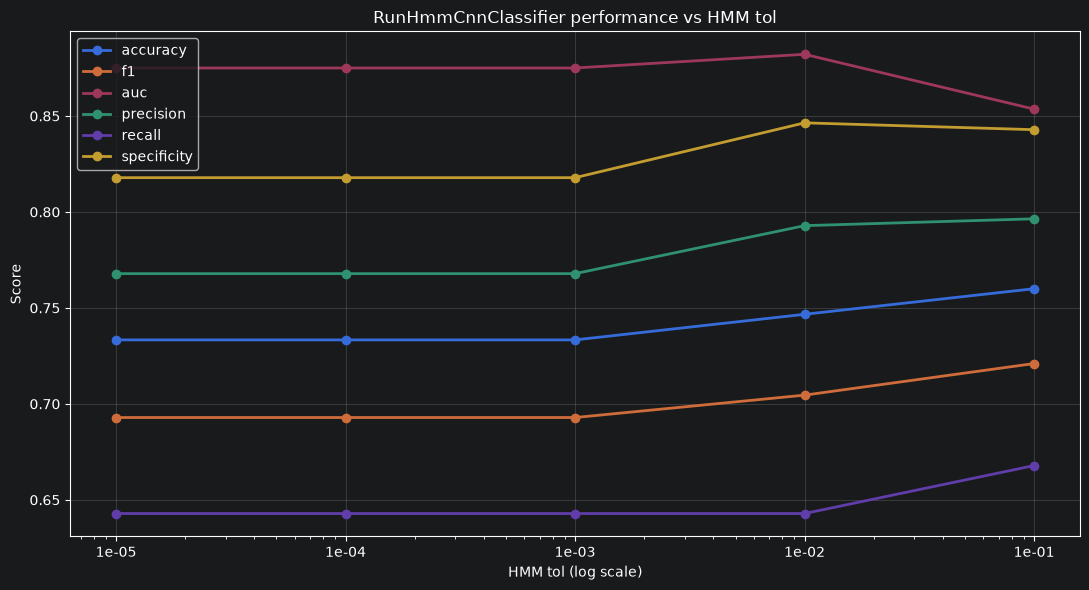


=== BEST HMM TOL ===
tol: 1e-02
Accuracy: 0.7467
F1: 0.7045
AUC: 0.8821
Precision: 0.7929
Recall: 0.6429
Specificity: 0.8464


In [2]:
# HMM TOL

tols = [1e-2, 1e-3, 1e-4, 1e-5]

results = []

for t in tols:

    print(
        f"\n=== Running experiment with tol={t:.0e} ==="
    )

    runner = RunHmmCnnClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=100,
        tol=t,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn(train seg - val no)/"
            f"hmm_tol/tol_{t}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "tol": t,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "tol"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_tol_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["tol"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xticks(
    df["tol"],
    [f"{t:.0e}" for t in df["tol"]]
)

plt.xlabel("HMM tol (log scale)")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnClassifier performance vs HMM tol"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM TOL ===")

print(
    f"tol: {best['tol']:.0e}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with n_iter=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6345 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7341 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6153 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6290 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7408 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6117 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6254

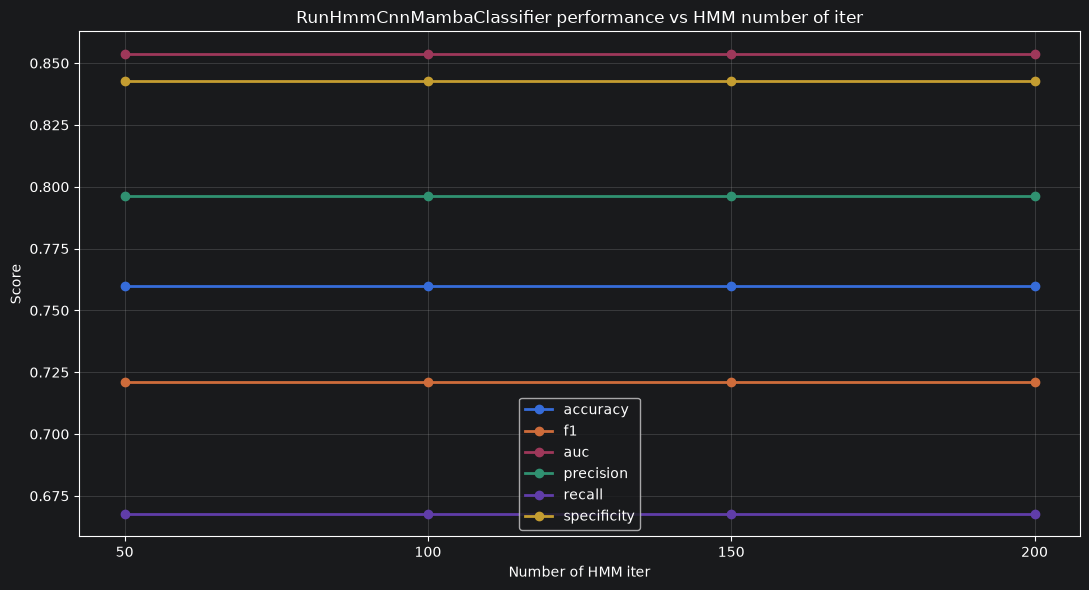


=== BEST HMM N_ITER ===
n_iter: 50
Accuracy: 0.7600
F1: 0.7210
AUC: 0.8536
Precision: 0.7964
Recall: 0.6679
Specificity: 0.8429


In [3]:
# HMM N_ITER

n_iter = [50, 100, 150, 200]

results = []

for i in n_iter:

    print(
        f"\n=== Running experiment with n_iter={i} ==="
    )

    runner = RunHmmCnnClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=i,
        tol=1e-1,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn(train seg - val no)/"
            f"hmm_n_iter/iter_{i}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "n_iter": i,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "n_iter"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_n_iter_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["n_iter"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["n_iter"]
)

plt.xlabel("Number of HMM iter")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of iter"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM N_ITER ===")

print(
    f"n_iter: {int(best['n_iter'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with epochs=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6345 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7341 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6153 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6290 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7408 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6117 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6254

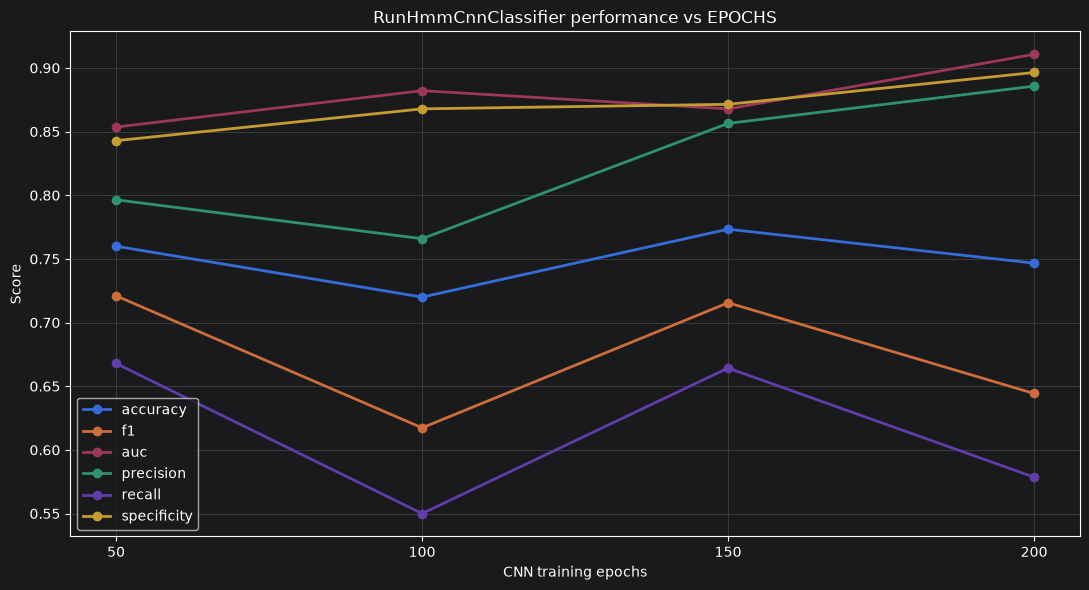


=== BEST EPOCHS ===
epochs: 200
Accuracy: 0.7467
F1: 0.6443
AUC: 0.9107
Precision: 0.8857
Recall: 0.5786
Specificity: 0.8964


In [4]:
# EPOCHS SWEEP

epochs = [50, 100, 150, 200]

results = []

for e in epochs:

    print(
        f"\n=== Running experiment with epochs={e} ==="
    )

    runner = RunHmmCnnClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=e,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-1,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn(train seg - val no)/"
            f"epochs/e_{e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "epochs": e,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "epochs"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_epochs_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["epochs"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["epochs"]
)

plt.xlabel("CNN training epochs")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnClassifier performance vs EPOCHS"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST EPOCHS ===")

print(
    f"epochs: {int(best['epochs'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with epochs=25 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6345 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7341 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6153 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6290 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7408 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6117 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8036 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6254

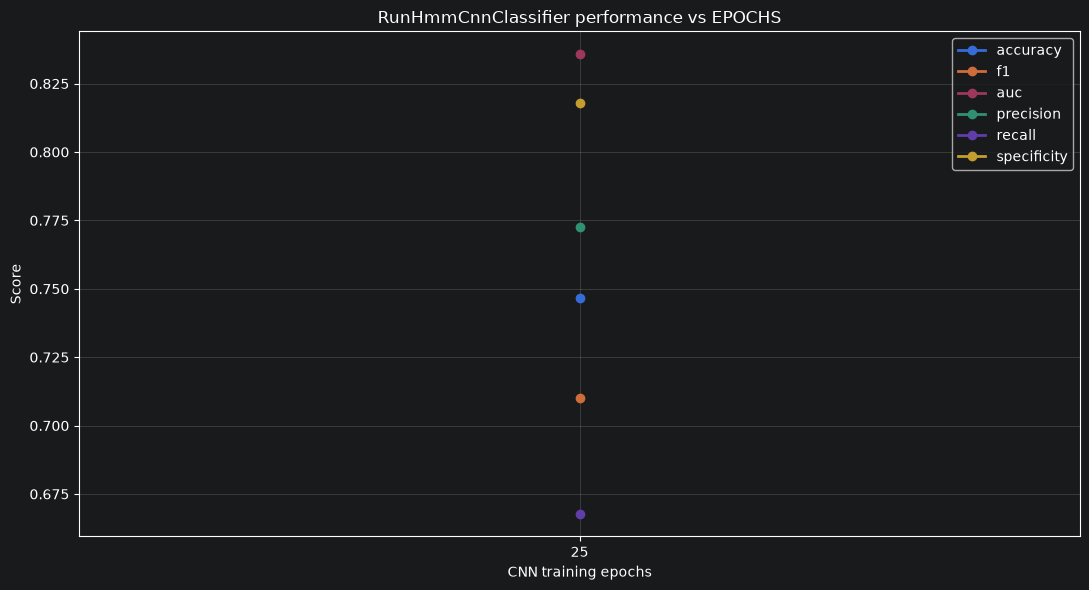


=== BEST EPOCHS ===
epochs: 25
Accuracy: 0.7467
F1: 0.7100
AUC: 0.8357
Precision: 0.7726
Recall: 0.6679
Specificity: 0.8179


In [5]:
# EPOCHS SWEEP

epochs = [25]

results = []

for e in epochs:

    print(
        f"\n=== Running experiment with epochs={e} ==="
    )

    runner = RunHmmCnnClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=e,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-1,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn(train seg - val no)/"
            f"epochs/e_{e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "epochs": e,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "epochs"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_epochs_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["epochs"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["epochs"]
)

plt.xlabel("CNN training epochs")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnClassifier performance vs EPOCHS"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST EPOCHS ===")

print(
    f"epochs: {int(best['epochs'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with learning_rate=0.01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6676 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7264 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6850 | val_accuracy=0.6667 | val_f1=0.7619 | val_auc=0.8571 | val_precision=0.6154 | val_recall=1.0000 | val_specificity=0.2857
Fold 01 | Epoch 02 | train_loss=0.6729 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7197 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6877 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.7679 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_lo

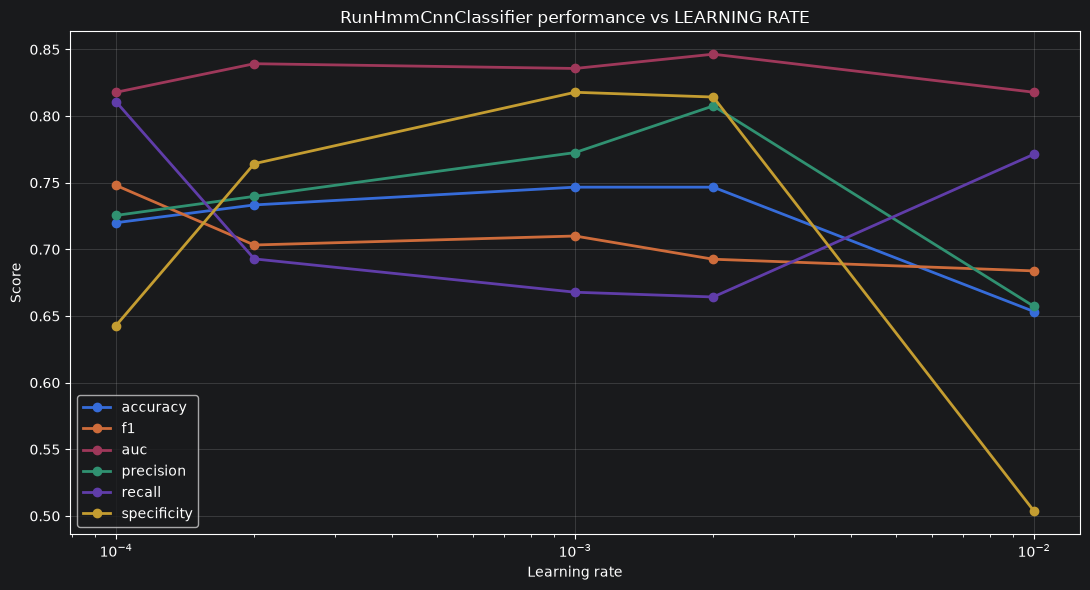


=== BEST LEARNING RATE ===
learning_rate: 0.002
Accuracy: 0.7467
F1: 0.6926
AUC: 0.8464
Precision: 0.8076
Recall: 0.6643
Specificity: 0.8143


In [6]:
# LEARNING RATE SWEEP

learning_rates = [1e-2, 1e-3, 1e-4, 2e-3, 2e-4]

results = []

for lr in learning_rates:

    print(
        f"\n=== Running experiment with learning_rate={lr} ==="
    )

    runner = RunHmmCnnClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=25,

        batch_size=16,

        learning_rate=lr,

        regularization=1e-6,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-1,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn(train seg - val no)/"
            f"learning_rate/lr_{lr}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "learning_rate": lr,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "learning_rate"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_learning_rate_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["learning_rate"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xlabel("Learning rate")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnClassifier performance vs LEARNING RATE"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST LEARNING RATE ===")

print(
    f"learning_rate: {best['learning_rate']}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with regularization=0.01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6788 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.7152 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.6982 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7679 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.6447 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7264 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6111 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.7679 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_l

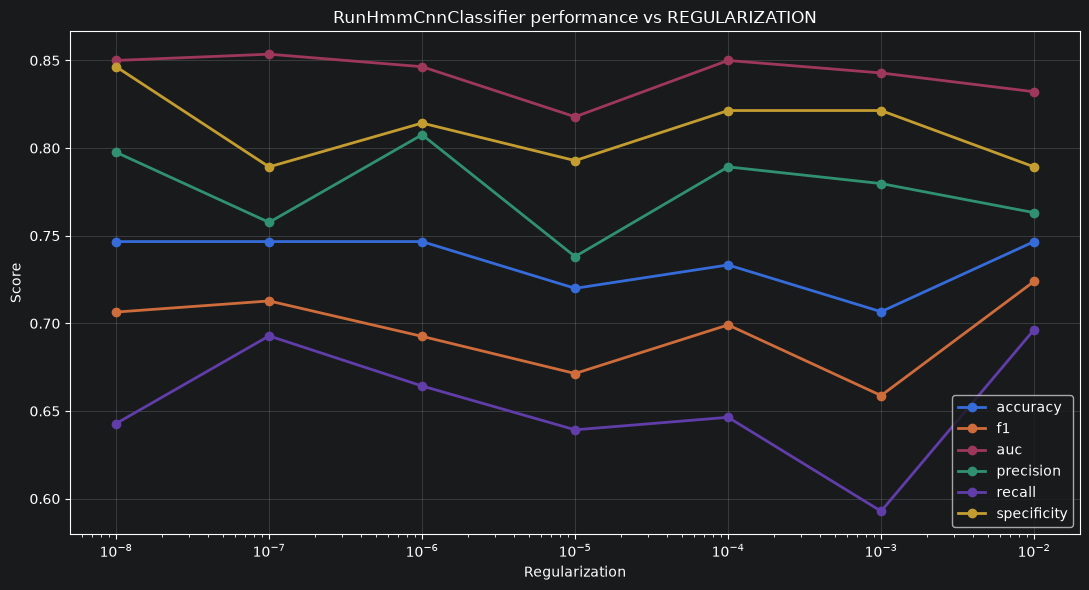


=== BEST REGULARIZATION ===
regularization: 1e-07
Accuracy: 0.7467
F1: 0.7128
AUC: 0.8536
Precision: 0.7576
Recall: 0.6929
Specificity: 0.7893


In [9]:
# REGULARIZATION SWEEP

regularizations = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]

results = []

for reg in regularizations:

    print(
        f"\n=== Running experiment with regularization={reg} ==="
    )

    runner = RunHmmCnnClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[1, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=25,

        batch_size=16,

        learning_rate=2e-3,

        regularization=reg,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=1e-1,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn(train seg - val no)/"
            f"regularization/reg_{reg}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "regularization": reg,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "regularization"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_regularization_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["regularization"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xlabel("Regularization")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnClassifier performance vs REGULARIZATION"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST REGULARIZATION ===")

print(
    f"regularization: {best['regularization']}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training CNN model...
Fold 01 | Epoch 01 | train_loss=0.6399 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7319 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6262 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8214 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6406 | train_accuracy=0.7333 | train_f1=0.7037 | train_auc=0.7353 | train_precision=0.7600 | train_recall=0.6552 | train_specificity=0.8065 | val_loss=0.6362 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8393 | val_precision=0.8571 | val_recall=0.7500 | val_specificity=0.8571
Fold 01 | Epoch 03 | train_loss=0.6278 | train_accuracy=0.7333 | train_f1=0.7037 

C:\Users\Utente\AppData\Local\Temp\ipykernel_20408\1918268557.py:145: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Utente\parkinson_disease\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


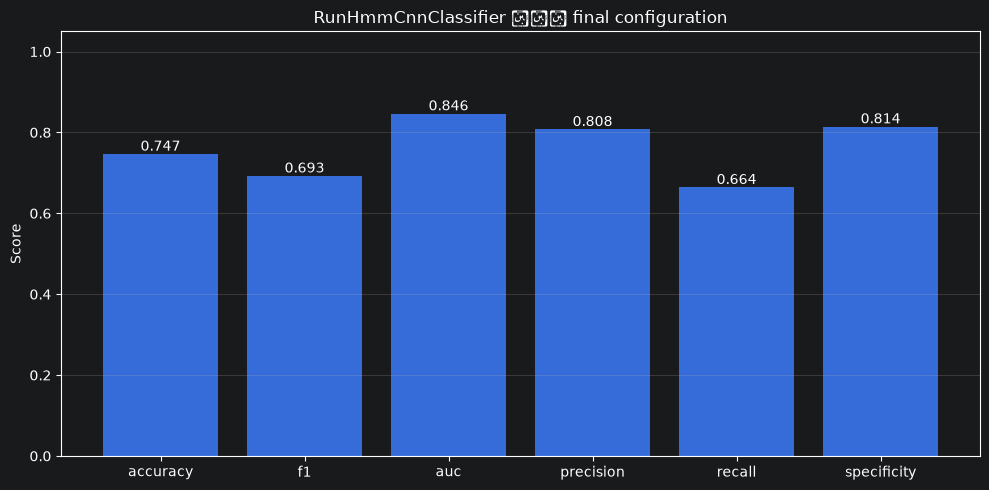


=== FINAL CONFIGURATION ===
Accuracy: 0.7467
F1: 0.6926
Auc: 0.8464
Precision: 0.8076
Recall: 0.6643
Specificity: 0.8143


In [10]:
# RUN HMM CNN CLASSIFIER

runner = RunHmmCnnClassifier(
    data_root=_project_path(
        "PaHaW/PaHaW/PaHaW_public"
    ),

    metadata_path=_project_path(
        "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
    ),

    # =====================================================
    # Configurazione dati
    # =====================================================

    tasks=[1, 8],

    feature_names=("x", "y"),

    engineered_features=(
        "pressure_derivative",
    ),

    # =====================================================
    # Training
    # =====================================================

    epochs=25,

    batch_size=16,

    learning_rate=2e-3,

    regularization=1e-6,

    # =====================================================
    # HMM
    # =====================================================

    n_states=2,
    covariance_type="diag",
    n_iter=50,
    tol=1e-1,
    random_state=42,
    algorithm="viterbi",
    verbose=False,

    n_splits=5,

    normalize=True,

    device=(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    ),

    output_dir=_project_path(
        "experiments/cnn1D/"
        "hmm(train seg - val no)/task_1_8/xy_pressure_derivative"
    ),

    training_cfg={
        "metrics": [
            "accuracy",
            "f1",
            "auc",
            "precision",
            "recall",
            "specificity",
        ],

        "monitor_metric": "auc",

        "early_stopping_patience": float("inf"),

        "min_delta": 0.0,

        "normalize": True,

        "normalization_eps": 1e-6,

        "results_writer": "csv",

        "save_metrics": True,
    },
)

summary = runner.run()


# =========================================================
# RISULTATI
# =========================================================

df = pd.DataFrame([summary["averages"]])

print("\n=== Summary ===")
print(df.T)

df.to_csv(
    "hmm_cnn_final_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

labels = [m.replace("val_", "") for m in metrics]
values = [summary["averages"][m] for m in metrics]

plt.figure(figsize=(10, 5))

bars = plt.bar(labels, values)

plt.bar_label(
    bars,
    fmt="%.3f"
)

plt.ylim(0, 1.05)
plt.ylabel("Score")

plt.title(
    "RunHmmCnnClassifier ﷿﷿﷿﷿﷿﷿﷿﷿﷿ final configuration"
)

plt.grid(
    True,
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# =========================================================
# FINAL METRICS
# =========================================================

print("\n=== FINAL CONFIGURATION ===")

for m, label in zip(metrics, labels):
    print(f"{label.capitalize()}: {summary['averages'][m]:.4f}")